In [1]:
import numpy as np

rng = np.random.default_rng(seed=2026)
n = 10000

fraccion_eva = 0.5

if not 0 <= fraccion_eva <= 1:
    raise ValueError("fraccion_eva debe estar entre 0 y 1.")

bits_alice = rng.integers(0, 2, size=n)
bases_alice = rng.integers(0, 2, size=n)

bases_bob = rng.integers(0, 2, size=n)

intercepta = rng.random(n) < fraccion_eva

bases_eva = rng.integers(0, 2, size=n)
aleatorios_eva = rng.integers(0, 2, size=n)

bits_eva = np.where(
    bases_alice == bases_eva,
    bits_alice,
    aleatorios_eva
)

bits_recibidos = np.where(
    intercepta,
    bits_eva,
    bits_alice
)

bases_recibidas = np.where(
    intercepta,
    bases_eva,
    bases_alice
)

aleatorios_bob = rng.integers(0, 2, size=n)

bits_bob_con_eva = np.where(
    bases_bob == bases_recibidas,
    bits_recibidos,
    aleatorios_bob
)

coinciden = bases_alice == bases_bob

clave_alice = bits_alice[coinciden]
clave_bob_con_eva = bits_bob_con_eva[coinciden]

total_conservados = len(clave_alice)
total_interceptados = np.sum(intercepta)

errores_con_eva = np.sum(
    clave_alice != clave_bob_con_eva
)

print("Qubits enviados:", n)
print(f"Probabilidad de interceptación: {fraccion_eva * 100:.2f}%")
print("Qubits interceptados:", total_interceptados)

print("\nClave cribada de Alice:", clave_alice)
print("Clave cribada de Bob:  ", clave_bob_con_eva)

print("\nBits conservados:", total_conservados)
print("Errores:", errores_con_eva)

if total_conservados > 0:
    qber_con_eva = errores_con_eva / total_conservados
    print(f"QBER simulado: {qber_con_eva * 100:.2f}%")
else:
    print("No se conservaron bits; no se puede calcular el QBER.")

qber_esperado = fraccion_eva / 4
print(f"QBER teórico esperado: {qber_esperado * 100:.2f}%")


Qubits enviados: 10000
Probabilidad de interceptación: 50.00%
Qubits interceptados: 5076

Clave cribada de Alice: [1 0 0 ... 0 1 1]
Clave cribada de Bob:   [1 0 0 ... 0 1 1]

Bits conservados: 4932
Errores: 621
QBER simulado: 12.59%
QBER teórico esperado: 12.50%


Interceptación | QBER simulado | QBER teórico
           0% |         0.00% |        0.00%
          10% |         2.33% |        2.50%
          20% |         4.56% |        5.00%
          30% |         7.24% |        7.50%
          40% |        10.22% |       10.00%
          50% |        12.78% |       12.50%
          60% |        14.79% |       15.00%
          70% |        16.88% |       17.50%
          80% |        19.37% |       20.00%
          90% |        21.87% |       22.50%
         100% |        23.98% |       25.00%


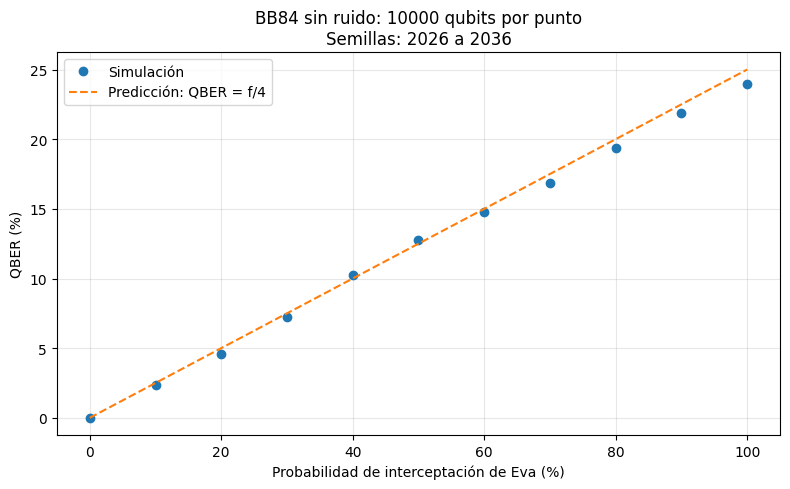

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def simular_qber(fraccion_eva, n, semilla):

    rng = np.random.default_rng(semilla)

    bits_alice = rng.integers(0, 2, size=n)
    bases_alice = rng.integers(0, 2, size=n)

    bases_bob = rng.integers(0, 2, size=n)

    intercepta = rng.random(n) < fraccion_eva

    bases_eva = rng.integers(0, 2, size=n)
    aleatorios_eva = rng.integers(0, 2, size=n)

    bits_eva = np.where(
        bases_alice == bases_eva,
        bits_alice,
        aleatorios_eva
    )

    bits_recibidos = np.where(
        intercepta, bits_eva, bits_alice
    )

    bases_recibidas = np.where(
        intercepta, bases_eva, bases_alice
    )

    aleatorios_bob = rng.integers(0, 2, size=n)

    bits_bob = np.where(
        bases_bob == bases_recibidas,
        bits_recibidos,
        aleatorios_bob
    )


    coinciden = bases_alice == bases_bob

    clave_alice = bits_alice[coinciden]
    clave_bob = bits_bob[coinciden]

    if len(clave_alice) == 0:
        return np.nan

    errores = np.sum(clave_alice != clave_bob)

    return errores / len(clave_alice)


n_grafica = 10000
semilla_inicial = 2026

fracciones = np.linspace(0, 1, 11)

qber_simulados = []

for i, fraccion in enumerate(fracciones):

    resultado = simular_qber(
        fraccion_eva=fraccion,
        n=n_grafica,
        semilla=semilla_inicial + i
    )

    qber_simulados.append(resultado)

qber_simulados = np.array(qber_simulados)

qber_teoricos = fracciones / 4

print("Interceptación | QBER simulado | QBER teórico")

for f, simulado, teorico in zip(
    fracciones, qber_simulados, qber_teoricos
):
    print(
        f"{f * 100:>12.0f}% |"
        f"{simulado * 100:>13.2f}% |"
        f"{teorico * 100:>12.2f}%"
    )

plt.figure(figsize=(8, 5))

plt.plot(
    fracciones * 100,
    qber_simulados * 100,
    "o",
    label="Simulación"
)

plt.plot(
    fracciones * 100,
    qber_teoricos * 100,
    "--",
    label="Predicción: QBER = f/4"
)

plt.xlabel("Probabilidad de interceptación de Eva (%)")
plt.ylabel("QBER (%)")

plt.title(
    f"BB84 sin ruido: {n_grafica} qubits por punto\n"
    f"Semillas: {semilla_inicial} a {semilla_inicial + 10}"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("BB84_QBER_vs_interceptacion.png", dpi=300)
plt.show()
